In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
url = "https://raw.githubusercontent.com/plotly/datasets/master/diabetes.csv"
df = pd.read_csv(url)

In [3]:
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [4]:
df.shape

(768, 9)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [6]:
df.isnull().sum()

,0
Pregnancies,0
Glucose,0
BloodPressure,0
SkinThickness,0
Insulin,0
BMI,0
DiabetesPedigreeFunction,0
Age,0
Outcome,0


In [7]:
df.duplicated().sum()

np.int64(0)

In [8]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Pregnancies,768.0,3.845052,3.369578,0.000,1.00000,3.0000,6.00000,17.00
Glucose,768.0,120.894531,31.972618,0.000,99.00000,117.0000,140.25000,199.00
BloodPressure,768.0,69.105469,19.355807,0.000,62.00000,72.0000,80.00000,122.00
SkinThickness,768.0,20.536458,15.952218,0.000,0.00000,23.0000,32.00000,99.00
Insulin,768.0,79.799479,115.244002,0.000,0.00000,30.5000,127.25000,846.00
BMI,768.0,31.992578,7.884160,0.000,27.30000,32.0000,36.60000,67.10
DiabetesPedigreeFunction,768.0,0.471876,0.331329,0.078,0.24375,0.3725,0.62625,2.42
Age,768.0,33.240885,11.760232,21.000,24.00000,29.0000,41.00000,81.00
Outcome,768.0,0.348958,0.476951,0.000,0.00000,0.0000,1.00000,1.00


In [9]:
df["Outcome"].value_counts()

,count
Outcome,
0,500
1,268


In [10]:
df["Outcome"].value_counts(normalize=True).mul(100).round(2)

,proportion
Outcome,
0,65.1
1,34.9


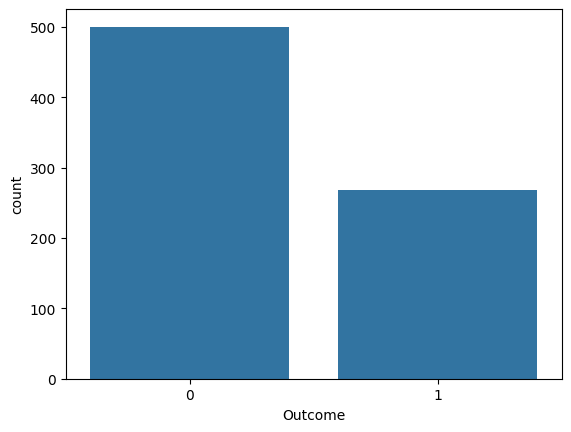

In [11]:
sns.countplot(data=df, x="Outcome")
plt.show()

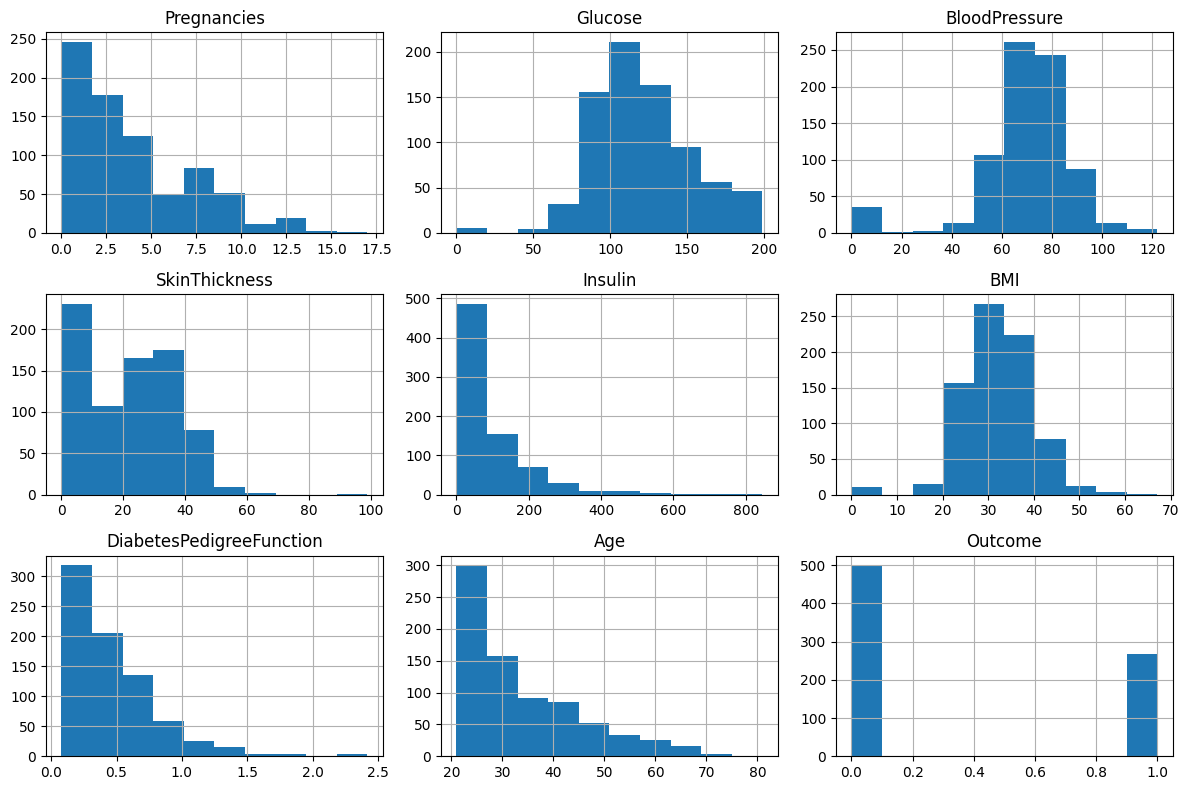

In [12]:
df.hist(figsize=(12, 8))
plt.tight_layout()
plt.show()

In [13]:
cols = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
(df[cols] == 0).sum()

,0
Glucose,5
BloodPressure,35
SkinThickness,227
Insulin,374
BMI,11


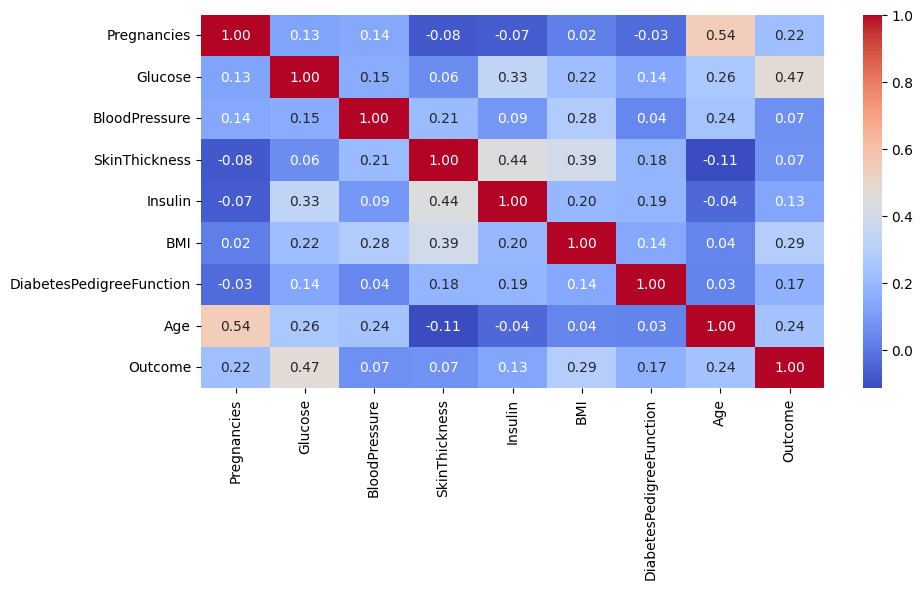

In [14]:
plt.figure(figsize=(10, 6))
sns.heatmap(df.corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.tight_layout()
plt.show()

In [15]:
X = df.drop(columns="Outcome")
y = df["Outcome"]

In [16]:
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

In [17]:
cols = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
X[cols] = X[cols].replace(0, np.nan)

In [18]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [19]:
preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

In [20]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score

In [21]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "SVM": SVC(probability=True, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42)
}

In [22]:
pipelines = {
    name: Pipeline([("preprocessor", preprocessor), ("model", model)])
    for name, model in models.items()
}

In [23]:
for name, pipe in pipelines.items():
    pipe.fit(X_train, y_train)
    print(f"{name}: trained")

Logistic Regression: trained
SVM: trained
Random Forest: trained


In [24]:
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score

results = pd.DataFrame({
    name: {
        "Accuracy": accuracy_score(y_test, pipe.predict(X_test)),
        "Precision": precision_score(y_test, pipe.predict(X_test), zero_division=0),
        "Recall": recall_score(y_test, pipe.predict(X_test), zero_division=0),
        "F1 Score": f1_score(y_test, pipe.predict(X_test), zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, pipe.predict_proba(X_test)[:, 1])
    }
    for name, pipe in pipelines.items()
}).T.sort_values("ROC-AUC", ascending=False)

results.round(3)

,Accuracy,Precision,Recall,F1 Score,ROC-AUC
Random Forest,0.747,0.660,0.574,0.614,0.816
Logistic Regression,0.708,0.600,0.500,0.545,0.813
SVM,0.740,0.652,0.556,0.600,0.796


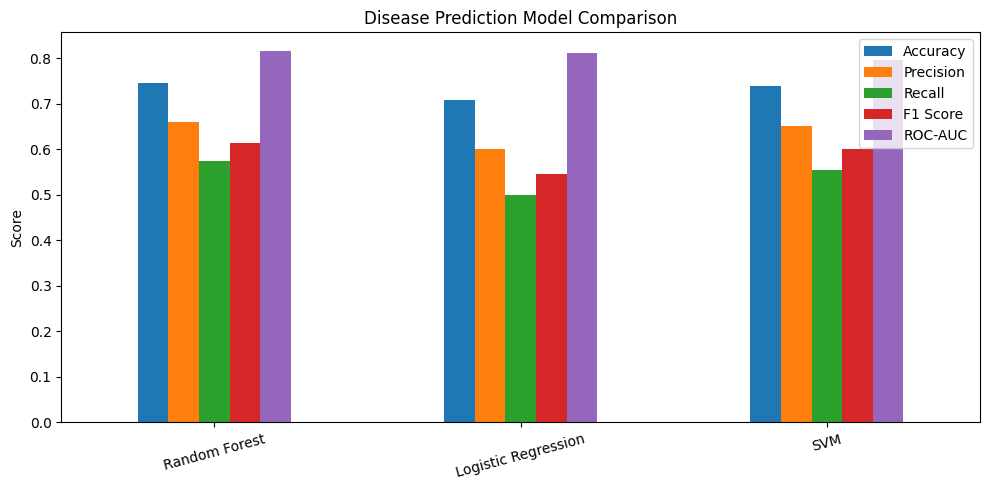

In [25]:
results.plot(kind="bar", figsize=(10, 5))
plt.title("Disease Prediction Model Comparison")
plt.ylabel("Score")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

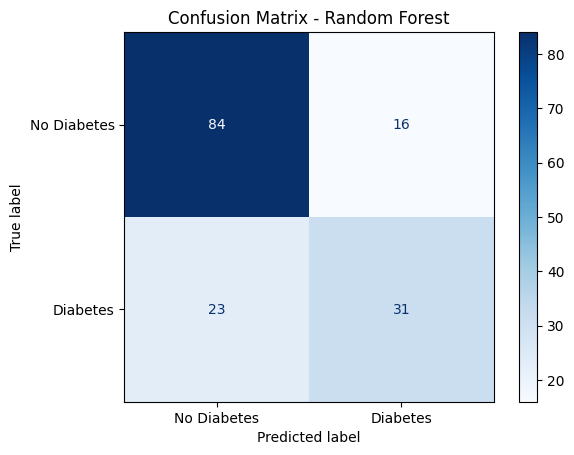

In [26]:
from sklearn.metrics import ConfusionMatrixDisplay

best_name = results.index[0]
best_model = pipelines[best_name]

ConfusionMatrixDisplay.from_estimator(
    best_model, X_test, y_test, display_labels=["No Diabetes", "Diabetes"],
    cmap="Blues"
)
plt.title(f"Confusion Matrix - {best_name}")
plt.show()

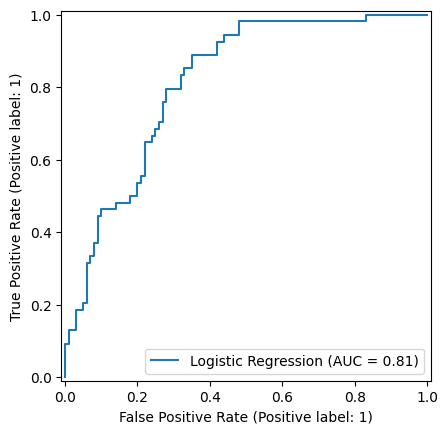

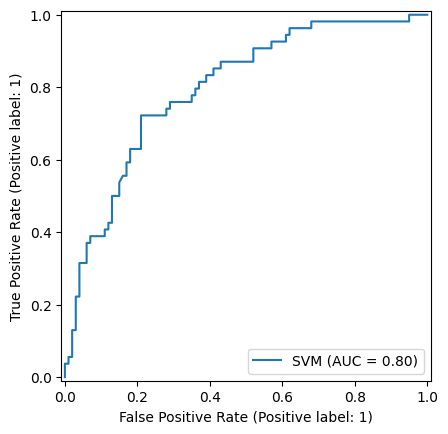

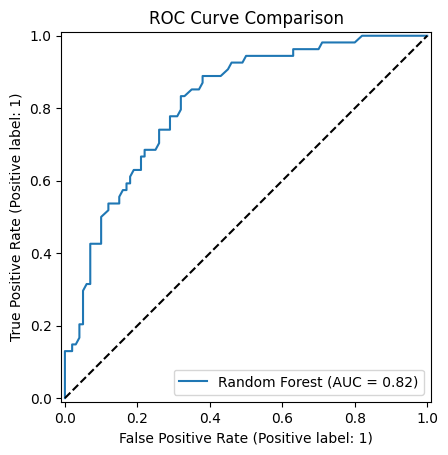

In [27]:
from sklearn.metrics import RocCurveDisplay

for name, pipe in pipelines.items():
    RocCurveDisplay.from_estimator(pipe, X_test, y_test, name=name)

plt.plot([0, 1], [0, 1], "k--")
plt.title("ROC Curve Comparison")
plt.legend()
plt.show()

In [28]:
from sklearn.inspection import permutation_importance

importance = permutation_importance(
    best_model, X_test, y_test, scoring="roc_auc", n_repeats=5, random_state=42
)

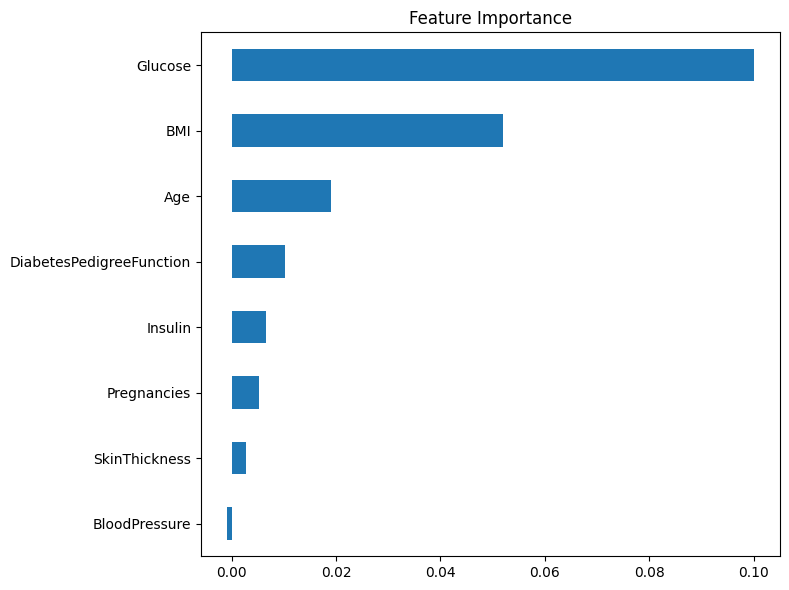

In [29]:
pd.Series(importance.importances_mean, index=X.columns).sort_values().plot(
    kind="barh", figsize=(8, 6), title="Feature Importance"
)
plt.tight_layout()
plt.show()

In [30]:
import joblib
from pathlib import Path

Path("models").mkdir(exist_ok=True)
joblib.dump(best_model, "models/diabetes_prediction_model.pkl")

['models/diabetes_prediction_model.pkl']

In [31]:
results.to_csv("model_comparison.csv")

In [32]:
print("Best model:", best_name)
display(results.round(3))

Best model: Random Forest


,Accuracy,Precision,Recall,F1 Score,ROC-AUC
Random Forest,0.747,0.660,0.574,0.614,0.816
Logistic Regression,0.708,0.600,0.500,0.545,0.813
SVM,0.740,0.652,0.556,0.600,0.796


In [33]:
print(classification_report(
    y_test, best_model.predict(X_test),
    target_names=["No Diabetes", "Diabetes"],
    zero_division=0
))

              precision    recall  f1-score   support

 No Diabetes       0.79      0.84      0.81       100
    Diabetes       0.66      0.57      0.61        54

    accuracy                           0.75       154
   macro avg       0.72      0.71      0.71       154
weighted avg       0.74      0.75      0.74       154



In [34]:
from sklearn.model_selection import cross_val_score

cv_results = {
    name: cross_val_score(pipe, X_train, y_train, cv=5, scoring="roc_auc")
    for name, pipe in pipelines.items()
}

pd.DataFrame({
    name: [scores.mean(), scores.std()]
    for name, scores in cv_results.items()
}, index=["Mean ROC-AUC", "Std ROC-AUC"]).T.round(3)

,Mean ROC-AUC,Std ROC-AUC
Logistic Regression,0.843,0.029
SVM,0.826,0.024
Random Forest,0.824,0.022


In [35]:
y_prob = best_model.predict_proba(X_test)[:, 1]

pd.DataFrame({
    "Actual": y_test.iloc[:10].values,
    "Predicted": best_model.predict(X_test.iloc[:10]),
    "Diabetes Probability": y_prob[:10].round(3)
})

,Actual,Predicted,Diabetes Probability
0,0,1,0.700
1,0,0,0.215
2,0,0,0.070
3,1,0,0.300
4,0,0,0.065
5,0,0,0.295
6,1,0,0.465
7,1,1,0.710
8,0,0,0.075
9,0,1,0.835


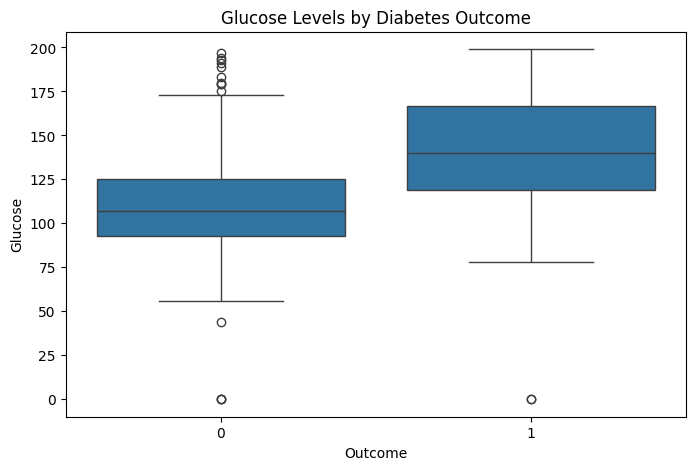

In [36]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="Outcome", y="Glucose")
plt.title("Glucose Levels by Diabetes Outcome")
plt.show()

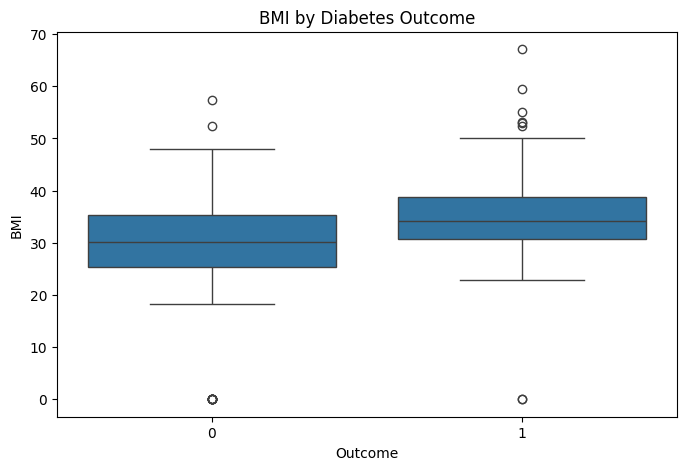

In [37]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="Outcome", y="BMI")
plt.title("BMI by Diabetes Outcome")
plt.show()

In [38]:
print("Dataset shape:", df.shape)
print("Best model:", best_name)
print("Best model ROC-AUC:", round(results.loc[best_name, "ROC-AUC"], 3))

Dataset shape: (768, 9)
Best model: Random Forest
Best model ROC-AUC: 0.816


In [39]:
Path("outputs").mkdir(exist_ok=True)

In [40]:
results.to_csv("outputs/model_comparison.csv")

In [41]:
plt.savefig("outputs/feature_importance.png", dpi=300, bbox_inches="tight")

<Figure size 640x480 with 0 Axes>

In [42]:
joblib.dump(best_model, "models/diabetes_prediction_model.pkl")

['models/diabetes_prediction_model.pkl']

In [43]:
print("Disease Prediction Model saved successfully.")

Disease Prediction Model saved successfully.


In [44]:
print("Best model:", best_name)
print("ROC-AUC:", round(results.loc[best_name, "ROC-AUC"], 3))
print("Saved files: models/diabetes_prediction_model.pkl, outputs/model_comparison.csv, outputs/feature_importance.png")

Best model: Random Forest
ROC-AUC: 0.816
Saved files: models/diabetes_prediction_model.pkl, outputs/model_comparison.csv, outputs/feature_importance.png


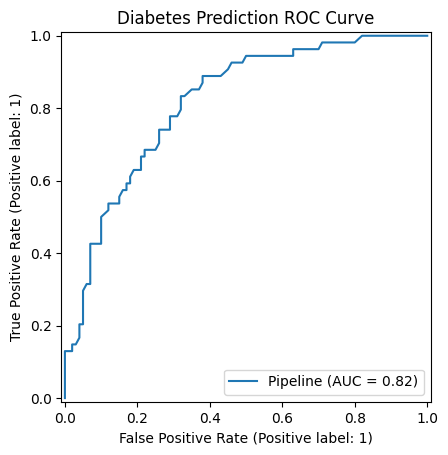

In [45]:
Path("outputs/roc_curve.png").parent.mkdir(exist_ok=True)
RocCurveDisplay.from_estimator(best_model, X_test, y_test)
plt.title("Diabetes Prediction ROC Curve")
plt.savefig("outputs/roc_curve.png", dpi=300, bbox_inches="tight")
plt.show()

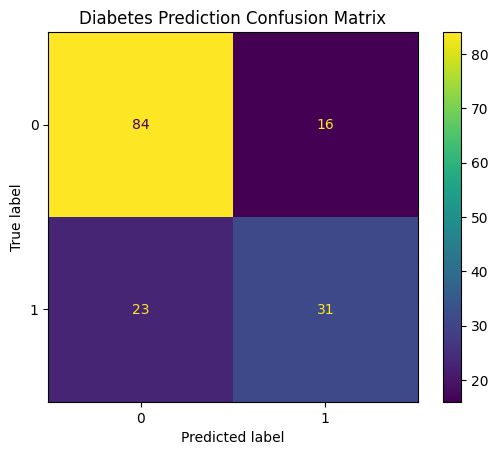

In [46]:
ConfusionMatrixDisplay.from_estimator(best_model, X_test, y_test)
plt.title("Diabetes Prediction Confusion Matrix")
plt.savefig("outputs/confusion_matrix.png", dpi=300, bbox_inches="tight")
plt.show()

In [47]:
results.round(3).to_csv("outputs/model_comparison.csv", index=True)

In [48]:
print("Notebook evaluation and visualizations completed.")

Notebook evaluation and visualizations completed.


In [49]:
print(sorted(str(p) for p in Path("outputs").glob("*")))

['outputs/confusion_matrix.png', 'outputs/feature_importance.png', 'outputs/model_comparison.csv', 'outputs/roc_curve.png']
